# Portion 6 — Statistics, journal figures, tables and the publication package (CPU)
**Inputs:** Portions 1–3, Portion 4 v2 and Portion 5. **Output:** `portion6_outputs/` (+ `publication_package.zip`). **Runtime:** ~2–4 min.

| Section | Output |
|---|---|
| 3 Statistics | every paired comparison of every endpoint (exact sign-flip test, 95 % CI, Cohen's d_z, BH-FDR over all endpoints); within-movie block bootstrap; probe and label-efficiency tests; a **claims table** with pre-defined decision rules |
| 4 Main figures 1–5 | rebuilt from the saved numbers (not screenshots): vector PDF + 600-dpi PNG + LZW TIFF at 183 mm width, 7-pt type, panel letters |
| 5 Supplementary figures | every analysis figure of Portions 1–5, renumbered S1…Sn with an index |
| 6 Tables | T1–T9 as CSV, LaTeX (booktabs) and one Excel workbook |
| 7 Text | figure legends and a results summary with every number filled in, methods parameters, reproducibility manifest |

**Decision rule used everywhere (fixed before looking at results):** with 5 held-out movies the smallest two-sided sign-flip p is 0.0625,
so a claim is **SUPPORTED** when the mean paired improvement is > 0 *and* it holds in ≥ 4 of 5 movies; **NOT SUPPORTED** when the mean
improvement is ≤ 0; otherwise **INCONCLUSIVE**. p, CI and d_z are always reported next to the verdict.

In [1]:
# ---- 0. Mount Google Drive -------------------------------------------------
try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

Mounted at /content/drive


In [2]:
# ---- 1. Imports & journal style ------------------------------------------------------------------------------
import os, json, glob, shutil, hashlib, itertools, platform, warnings, logging, zipfile
from datetime import datetime
import numpy as np
import pandas as pd
from scipy import ndimage as ndi
from scipy.stats import t as t_dist
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import matplotlib.patheffects as pe
from matplotlib import font_manager
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import FancyBboxPatch
from IPython.display import display
warnings.filterwarnings('ignore'); logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)
MM = 1 / 25.4; W1, W15, W2 = 89 * MM, 120 * MM, 183 * MM
_avail = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans'] if f in _avail), 'DejaVu Sans')
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': [FONT], 'font.size': 7, 'axes.titlesize': 7,
                     'axes.labelsize': 7, 'xtick.labelsize': 6.3, 'ytick.labelsize': 6.3, 'legend.fontsize': 6,
                     'axes.linewidth': 0.6, 'xtick.major.width': 0.6, 'ytick.major.width': 0.6, 'xtick.major.size': 2.5,
                     'ytick.major.size': 2.5, 'lines.linewidth': 1.1, 'lines.markersize': 3.5, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False, 'legend.frameon': False, 'figure.dpi': 150,
                     'savefig.dpi': 600, 'pdf.fonttype': 42, 'ps.fonttype': 42, 'axes.titlelocation': 'left'})
def panel(ax, s, x=-0.16, y=1.03):
    ax.text(x, y, s, transform=ax.transAxes, fontsize=9, fontweight='bold', va='bottom', ha='left')
print('numpy', np.__version__, '| pandas', pd.__version__, '| matplotlib', matplotlib.__version__, '| font', FONT)

numpy 2.1.3 | pandas 2.2.3 | matplotlib 3.10.0 | font Liberation Sans


In [3]:
# ---- 2. Configuration and inputs -------------------------------------------------------------------------------
DATA_DIR = '/content/drive/MyDrive/Koushik-experiment/'
DATA_DIR = os.environ.get('HSAFM_DATA_DIR', DATA_DIR)          # (local-testing override; ignore in Colab)
P = {i: os.path.join(DATA_DIR, f'portion{i}_outputs') for i in (1, 2, 3, 5)}
P[4] = os.path.join(DATA_DIR, 'portion4_v2_outputs')
OUT = os.path.join(DATA_DIR, 'portion6_outputs')
FIG, SUP, TAB, TXT = [os.path.join(OUT, d) for d in ('main_figures', 'supplementary_figures', 'tables', 'text')]
for d in [OUT, FIG, SUP, TAB, TXT]:
    os.makedirs(d, exist_ok=True)
need = {1: ['frames_all.csv', 'sessions.csv', 'splits.json'], 2: ['targets_per_frame.csv', 'repeatability_trace_retrace.csv'],
        3: ['dataset_index.csv', 'dataset_5nm_f16.npy', 'probe_results_per_fold.csv', 'run_config_portion3.json'],
        4: ['metrics_all_v2.csv', 'skill_vs_persistence.csv', 'kinetics_clean.csv', 'run_config_portion4_v2.json'],
        5: ['label_efficiency.csv', 'robustness.csv', 'attribution_stats.csv', 'failure_cases.csv']}
missing = [os.path.join(P[k], f) for k, fs in need.items() for f in fs if not os.path.exists(os.path.join(P[k], f))]
assert not missing, 'Run the earlier portions first. Missing:\n' + '\n'.join(missing)
N_BOOT, BLOCK_S, SEED = 2000, 60.0, 0
SUPPORT_MIN_FRAC = 0.8                      # SUPPORTED needs the improvement in >= 80 % of held-out movies (4 of 5)
conc_order = lambda c: float(str(c).replace('nM', ''))
frames = pd.read_csv(os.path.join(P[1], 'frames_all.csv')); sessions = pd.read_csv(os.path.join(P[1], 'sessions.csv'))
splits = json.load(open(os.path.join(P[1], 'splits.json')))['splits']
tg = pd.read_csv(os.path.join(P[2], 'targets_per_frame.csv'))
idx = pd.read_csv(os.path.join(P[3], 'dataset_index.csv'))
p3cfg = json.load(open(os.path.join(P[3], 'run_config_portion3.json'))); p4cfg = json.load(open(os.path.join(P[4], 'run_config_portion4_v2.json')))
QUICK = bool(p3cfg.get('QUICK', False))
MET = pd.read_csv(os.path.join(P[4], 'metrics_all_v2.csv'))
HORIZONS = tuple(p4cfg['config']['HORIZONS']); PH = 30.0 if 30.0 in HORIZONS else HORIZONS[len(HORIZONS) // 2]
SELECTED, PROPOSED = 'nested-selected', p4cfg['config'].get('PROPOSED', 'B4+phys')
MODELS = list(dict.fromkeys(MET.model))
loco = sorted([s for s in MET.split.unique() if s.startswith('LOCO_')], key=lambda s: conc_order(s.split('_')[1]))
CONCS = sorted(idx.conc.unique(), key=conc_order); NF = len(loco)
streak = idx.frame_id.map(frames.set_index('frame_id').warn_streaks).fillna(False).astype(bool).values
lab = idx.join(tg.set_index('frame_id')[['coverage', 'contrast_ok', 'fft_peak_ratio', 'density_um2', 'regime']], on='frame_id')
lab.loc[streak, ['coverage', 'fft_peak_ratio', 'density_um2']] = np.nan
CCOL = {c: plt.get_cmap('Blues')(0.38 + 0.54 * i / max(1, len(CONCS) - 1)) for i, c in enumerate(CONCS)}   # 2-10 nM ramp (no 12 nM)
VCOL = {'B0': '#9a9a9a', 'B2': '#1baf7a', 'B3': '#eb6834', 'B4': '#2a78d6', 'B5': '#eda100'}
MCOL = {'persistence': '#b5b5b5', 'linear': '#8f8f8f', 'kinetic': '#5c5c5c', 'MLP-desc': '#3a3a3a', 'B0': '#cfcfcf', 'B2': '#1baf7a',
        'B3': '#eb6834', 'B4': '#6250d6', 'B5': '#e87ba4', 'B5+phys': '#eda100', 'B4+phys': '#2a78d6', SELECTED: '#0b0b0b'}
TNAME = {'coverage': 'coverage θ', 'log_peak': 'lattice sharpness', 'psi6': 'ψ6 (dense)', 'log_density': 'density (sparse)'}
print(f'{len(CONCS)} movies {CONCS} | {NF} LOCO folds | models: {MODELS} | Portion-3 QUICK={QUICK}')

def save(fig, name, folder=FIG):
    fig.savefig(os.path.join(folder, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(folder, f'{name}.png'), bbox_inches='tight', dpi=600)
    try:
        fig.savefig(os.path.join(folder, f'{name}.tiff'), bbox_inches='tight', dpi=600, pil_kwargs={'compression': 'tiff_lzw'})
    except Exception as e:
        print('TIFF export skipped:', e)
    plt.show()

5 movies ['2nM', '4nM', '6nM', '8nM', '10nM'] | 5 LOCO folds | models: ['persistence', 'linear', 'kinetic', 'MLP-desc', 'B0', 'B2', 'B3', 'B4', 'B5', 'B4+phys', 'B5+phys', 'nested-selected'] | Portion-3 QUICK=False


In [4]:
# ---- 3. Statistics -------------------------------------------------------------------------------------------------
def signflip_p(d):
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n == 0: return np.nan
    signs = np.array(list(itertools.product([-1, 1], repeat=n)))
    return float(np.mean(np.abs((signs * d).mean(1)) >= abs(d.mean()) - 1e-12))
def bh(p):
    p = np.asarray(p, float); n = np.sum(np.isfinite(p)); o = np.argsort(np.where(np.isfinite(p), p, np.inf))
    q = np.full_like(p, np.nan); prev = 1.0
    for rank, i in reversed(list(enumerate(o[:n], start=1))):
        prev = min(prev, p[i] * n / rank); q[i] = prev
    return q
def paired_row(d):
    """d = per-movie improvement (> 0 = reference better)."""
    d = np.asarray(d, float); d = d[np.isfinite(d)]; n = len(d)
    if n < 2: return dict(n=n, improvement=np.nan, CI95_low=np.nan, CI95_high=np.nan, cohens_dz=np.nan, won=0, p=np.nan)
    sd = d.std(ddof=1); ci = t_dist.ppf(0.975, n - 1) * sd / np.sqrt(n)
    return dict(n=n, improvement=d.mean(), CI95_low=d.mean() - ci, CI95_high=d.mean() + ci, cohens_dz=d.mean() / sd if sd > 0 else np.nan,
                won=int((d > 0).sum()), p=signflip_p(d))
def verdict(r):
    if not np.isfinite(r['improvement']): return 'INCONCLUSIVE'
    if r['improvement'] <= 0: return 'NOT SUPPORTED'
    return 'SUPPORTED' if r['won'] >= int(np.ceil(SUPPORT_MIN_FRAC * r['n'])) else 'INCONCLUSIVE'

# 3a  every endpoint: reference vs every comparator, paired over held-out movies
Lm = MET[MET.split.isin(loco)]
st = []
for (ph, tn, h), g in Lm.groupby(['phase', 'target', 'horizon']):
    t = g.pivot(index='model', columns='test', values='MAE')
    for ref in [SELECTED, PROPOSED]:
        if ref not in t.index: continue
        for comp in t.index:
            if comp == ref: continue
            r = paired_row((t.loc[comp] - t.loc[ref]).values)
            st.append(dict(phase=ph, target=tn, horizon=h, reference=ref, comparator=comp, MAE_reference=t.loc[ref].mean(),
                           MAE_comparator=t.loc[comp].mean(), **r))
ST = pd.DataFrame(st); ST['q_BH'] = bh(ST.p.values); ST['verdict'] = ST.apply(verdict, axis=1)
ST.to_csv(os.path.join(OUT, 'statistics_all_endpoints.csv'), index=False)
print(f'{len(ST)} paired comparisons; smallest attainable two-sided p with {NF} movies = {2/2**NF:.4f}')
display(ST[(ST.target == 'coverage') & (ST.horizon == PH) & (ST.reference == SELECTED)].round(4))

# 3b  within-movie block bootstrap (secondary uncertainty) - vectorised
lab_t, lab_cov = lab.t_rel_s.values, lab.coverage.values
boot = []; rng = np.random.default_rng(SEED); hp = HORIZONS.index(PH)
for s in loco:
    f = os.path.join(P[4], 'predictions', f'{s}.npz')
    if not os.path.exists(f): continue
    R = np.load(f, allow_pickle=True); te = R['te_rows']; c = splits[s]['test'][0]
    rr = np.where(lab.conc.values == c)[0]; tt = lab_t[rr]
    j = np.searchsorted(tt, lab_t[te] + PH).clip(0, len(tt) - 1)
    ok = (np.abs(tt[j] - (lab_t[te] + PH)) <= 3) & np.isfinite(lab_cov[rr[j]]); yo = lab_cov[rr[j]]
    blocks = (lab_t[te] // BLOCK_S).astype(int); ub = np.unique(blocks[ok])
    if len(ub) < 3: continue
    bidx = np.searchsorted(ub, blocks); counts = rng.multinomial(len(ub), np.ones(len(ub)) / len(ub), size=N_BOOT)   # (B, n_blocks)
    e_per = np.abs(R['persistence'].mean(0)[:, hp, 0] - yo)
    for ref in [m for m in [SELECTED, PROPOSED, 'kinetic'] if m in R.files]:
        e_ref = np.abs(R[ref].mean(0)[:, hp, 0] - yo); dlt = np.where(ok, e_per - e_ref, 0.0)
        bs = np.bincount(bidx[ok], weights=dlt[ok], minlength=len(ub)); bn = np.bincount(bidx[ok], minlength=len(ub))
        diffs = (counts @ bs) / np.maximum(counts @ bn, 1)
        boot.append(dict(test=c, model=ref, improvement_vs_persistence=float(dlt[ok].mean()), CI95_low=float(np.percentile(diffs, 2.5)),
                         CI95_high=float(np.percentile(diffs, 97.5)), n_anchors=int(ok.sum()), n_blocks=len(ub)))
BOOT = pd.DataFrame(boot); BOOT.to_csv(os.path.join(OUT, 'block_bootstrap_vs_persistence.csv'), index=False); display(BOOT.round(4))

# 3c  representation probes (Portion 3) and label efficiency (Portion 5)
PR = pd.read_csv(os.path.join(P[3], 'probe_results_per_fold.csv'))
pst = []
for pn, g in PR.groupby('probe'):
    t = g.pivot(index='variant', columns='test', values='value'); better_high = g.metric.iloc[0] != 'MAE'
    for ref, comp in [('B4', 'B0'), ('B4', 'B2'), ('B4', 'B3'), ('B4', 'B5'), ('B3', 'B0')]:
        if ref in t.index and comp in t.index:
            d = (t.loc[ref] - t.loc[comp]).values if better_high else (t.loc[comp] - t.loc[ref]).values
            pst.append(dict(probe=pn, metric=g.metric.iloc[0], reference=ref, comparator=comp, **paired_row(d)))
PST = pd.DataFrame(pst)
if len(PST): PST['q_BH'] = bh(PST.p.values); PST['verdict'] = PST.apply(verdict, axis=1)
PST.to_csv(os.path.join(OUT, 'statistics_probes.csv'), index=False)
LE = pd.read_csv(os.path.join(P[5], 'label_efficiency.csv'))
_trapz = getattr(np, 'trapezoid', None) or np.trapz
auc = LE.groupby(['probe', 'variant', 'split', 'fraction']).MAE.mean().reset_index(); auc['logf'] = np.log10(auc.fraction)
AUC = pd.DataFrame([dict(probe=k[0], variant=k[1], split=k[2],
                         AUC=float(_trapz(g.sort_values('logf').MAE.values, g.sort_values('logf').logf.values) / max(1e-9, g.logf.max() - g.logf.min())))
                    for k, g in auc.groupby(['probe', 'variant', 'split']) if len(g) > 1])
lst = []
for pn, g in AUC.groupby('probe'):
    t = g.pivot(index='variant', columns='split', values='AUC')
    for comp in [v for v in ['B0', 'B2', 'B3', 'B5'] if v in t.index]:
        if 'B4' in t.index:
            lst.append(dict(probe=pn, reference='B4', comparator=comp, **paired_row((t.loc[comp] - t.loc['B4']).values)))
LST = pd.DataFrame(lst)
if len(LST): LST['verdict'] = LST.apply(verdict, axis=1)
LST.to_csv(os.path.join(OUT, 'statistics_label_efficiency.csv'), index=False)

# 3d  claims table
def claim(cid, text, row, metric):
    return dict(id=cid, claim=text, metric=metric, improvement=row.get('improvement', np.nan), CI95_low=row.get('CI95_low', np.nan),
                CI95_high=row.get('CI95_high', np.nan), cohens_dz=row.get('cohens_dz', np.nan),
                movies=f"{row.get('won', 0)}/{row.get('n', 0)}", p=row.get('p', np.nan), verdict=verdict(row) if row else 'INCONCLUSIVE')
def st_row(phase, target, horizon, ref, comp):
    d = ST[(ST.phase == phase) & (ST.target == target) & (ST.horizon == horizon) & (ST.reference == ref) & (ST.comparator == comp)]
    return d.iloc[0].to_dict() if len(d) else {}
def pst_row(probe, ref, comp):
    d = PST[(PST.probe == probe) & (PST.reference == ref) & (PST.comparator == comp)] if len(PST) else PST
    return d.iloc[0].to_dict() if len(d) else {}
C = []
C.append(claim('C1', 'Self-supervised temporal pretraining (B4) beats random init on the coverage probe', pst_row('coverage', 'B4', 'B0'), 'probe MAE'))
C.append(claim('C2', 'True time order matters for representations (B4 vs shuffled B5, dynamics probe)', pst_row('Δcoverage +30 s', 'B4', 'B5'), 'probe MAE'))
C.append(claim('C3', 'Temporal InfoNCE adds to temporal MAE (B4 vs B3, coverage probe)', pst_row('coverage', 'B4', 'B3'), 'probe MAE'))
C.append(claim('C4', f'Nested-selected forecast beats persistence (coverage +{PH:.0f} s, all anchors)', st_row('all', 'coverage', PH, SELECTED, 'persistence'), 'MAE'))
C.append(claim('C5', f'Nested-selected forecast beats the kinetic fit (coverage +{PH:.0f} s, all anchors)', st_row('all', 'coverage', PH, SELECTED, 'kinetic'), 'MAE'))
C.append(claim('C6', f'Nested-selected beats persistence during assembly (coverage +{PH:.0f} s)', st_row('assembly', 'coverage', PH, SELECTED, 'persistence'), 'MAE'))
for k, (tn, h) in enumerate([('log_density', 30.0), ('log_peak', 60.0)]):
    if h in HORIZONS:
        C.append(claim(f'C{7+k}', f'Structure forecast beats persistence: {TNAME[tn]} +{h:.0f} s', st_row('all', tn, h, SELECTED, 'persistence'), 'MAE'))
C.append(claim('C9', f'Physics loss helps the proposed head (B4+phys vs B4, coverage +{PH:.0f} s)', st_row('all', 'coverage', PH, PROPOSED, 'B4'), 'MAE'))
CLAIMS = pd.DataFrame(C); CLAIMS.to_csv(os.path.join(OUT, 'claims_table.csv'), index=False); display(CLAIMS.round(4))

528 paired comparisons; smallest attainable two-sided p with 5 movies = 0.0625


,phase,target,horizon,reference,comparator,MAE_reference,MAE_comparator,n,improvement,CI95_low,CI95_high,cohens_dz,won,p,q_BH,verdict
22,all,coverage,30.0,nested-selected,B0,0.0285,0.0216,5,-0.0068,-0.0120,-0.0016,-1.6115,1,0.1250,0.7021,NOT SUPPORTED
23,all,coverage,30.0,nested-selected,B2,0.0285,0.0225,5,-0.0059,-0.0111,-0.0008,-1.4366,0,0.0625,0.6875,NOT SUPPORTED
24,all,coverage,30.0,nested-selected,B3,0.0285,0.0254,5,-0.0031,-0.0095,0.0034,-0.5845,2,0.3750,0.9659,NOT SUPPORTED
25,all,coverage,30.0,nested-selected,B4,0.0285,0.0374,5,0.0089,-0.0300,0.0479,0.2846,2,0.9375,1.0000,INCONCLUSIVE
26,all,coverage,30.0,nested-selected,B4+phys,0.0285,0.0325,5,0.0041,-0.0237,0.0319,0.1825,1,1.0000,1.0000,INCONCLUSIVE
27,all,coverage,30.0,nested-selected,B5,0.0285,0.0342,5,0.0058,-0.0230,0.0345,0.2489,2,0.9375,1.0000,INCONCLUSIVE
28,all,coverage,30.0,nested-selected,B5+phys,0.0285,0.0291,5,0.0007,-0.0153,0.0167,0.0538,2,0.9375,1.0000,INCONCLUSIVE
29,all,coverage,30.0,nested-selected,MLP-desc,0.0285,0.0229,5,-0.0056,-0.0107,-0.0005,-1.3524,0,0.1250,0.7021,NOT SUPPORTED
30,all,coverage,30.0,nested-selected,kinetic,0.0285,0.0194,5,-0.0091,-0.0215,0.0033,-0.9097,0,0.0625,0.6875,NOT SUPPORTED
31,all,coverage,30.0,nested-selected,linear,0.0285,0.0209,5,-0.0076,-0.0206,0.0055,-0.7219,1,0.1875,0.8390,NOT SUPPORTED


,test,model,improvement_vs_persistence,CI95_low,CI95_high,n_anchors,n_blocks
0,2nM,nested-selected,-0.0389,-0.0479,-0.0313,566,10
1,2nM,B4+phys,-0.0826,-0.0887,-0.0765,566,10
2,2nM,kinetic,-0.0126,-0.0191,-0.0058,566,10
3,4nM,nested-selected,0.0000,0.0000,0.0000,854,20
4,4nM,B4+phys,0.0011,-0.0063,0.0070,854,20
5,4nM,kinetic,0.0011,-0.0026,0.0039,854,20
6,6nM,nested-selected,0.0000,0.0000,0.0000,783,18
7,6nM,B4+phys,0.0105,0.0003,0.0254,783,18
8,6nM,kinetic,0.0074,0.0003,0.0176,783,18
9,8nM,nested-selected,0.0000,0.0000,0.0000,794,20


,id,claim,metric,improvement,CI95_low,CI95_high,cohens_dz,movies,p,verdict
0,C1,Self-supervised temporal pretraining (B4) beat...,probe MAE,0.0712,-0.0486,0.1910,0.7380,5/5,0.0625,SUPPORTED
1,C2,True time order matters for representations (B...,probe MAE,0.0042,-0.0001,0.0084,1.2233,5/5,0.0625,SUPPORTED
2,C3,Temporal InfoNCE adds to temporal MAE (B4 vs B...,probe MAE,-0.0155,-0.0357,0.0047,-0.9527,1/5,0.1875,NOT SUPPORTED
3,C4,Nested-selected forecast beats persistence (co...,MAE,-0.0077,-0.0292,0.0137,-0.4472,0/5,1.0000,NOT SUPPORTED
4,C5,Nested-selected forecast beats the kinetic fit...,MAE,-0.0091,-0.0215,0.0033,-0.9097,0/5,0.0625,NOT SUPPORTED
5,C6,Nested-selected beats persistence during assem...,MAE,-0.0077,-0.0292,0.0137,-0.4472,0/5,1.0000,NOT SUPPORTED
6,C7,Structure forecast beats persistence: density ...,MAE,0.0338,-0.1414,0.2090,0.3073,1/4,1.0000,INCONCLUSIVE
7,C8,Structure forecast beats persistence: lattice ...,MAE,0.0312,-0.0562,0.1186,0.4428,4/5,0.3750,SUPPORTED
8,C9,Physics loss helps the proposed head (B4+phys ...,MAE,0.0048,-0.0064,0.0161,0.5328,4/5,0.1875,SUPPORTED


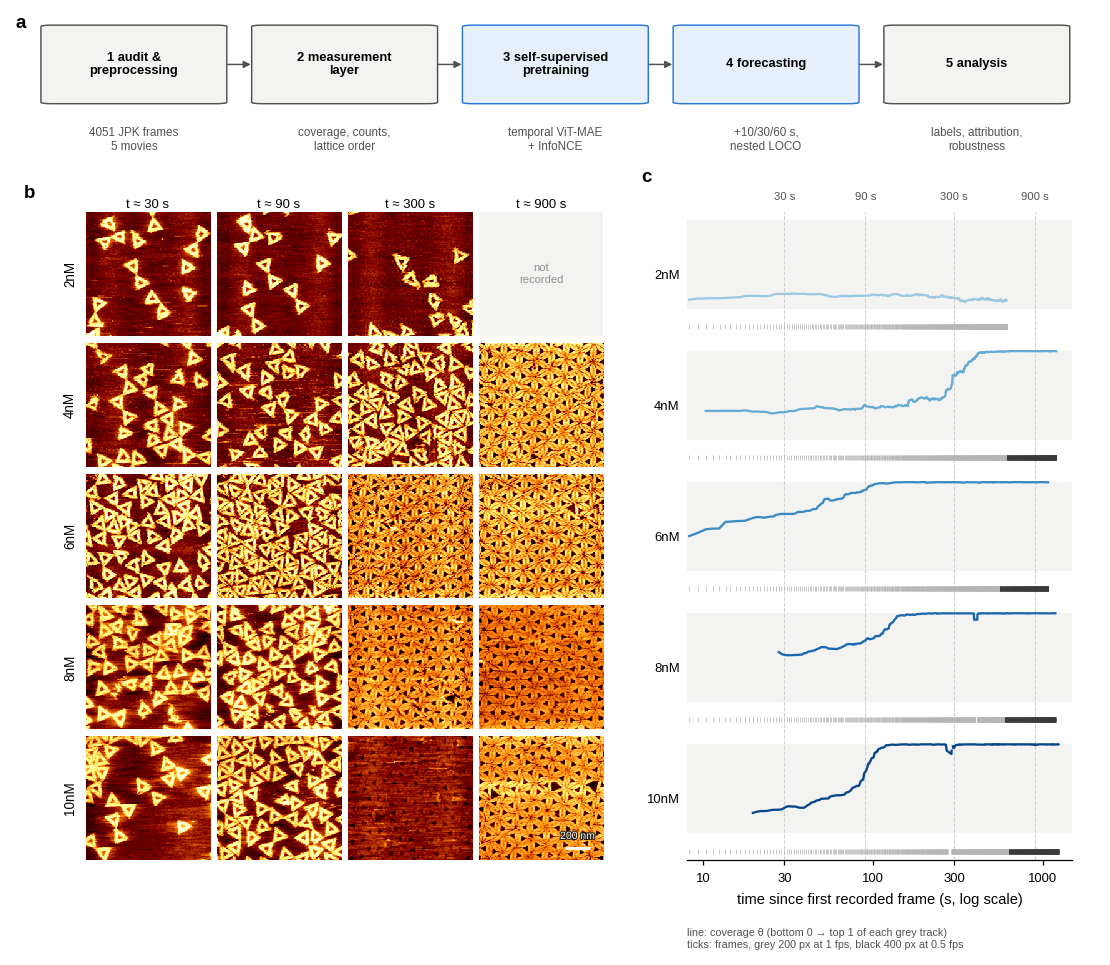

In [5]:
# ---- 4a. Figure 1 — data and workflow --------------------------------------------------------------------------------
X = np.load(os.path.join(P[3], 'dataset_5nm_f16.npy'), mmap_mode='r'); H0 = X.shape[1]
def box(ax, x, y, w, h, text, fc='#ffffff', ec='#52514e', fs=6, bold=False):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle='round,pad=0.006,rounding_size=0.01', fc=fc, ec=ec, lw=0.7))
    ax.text(x + w / 2, y + h / 2, text, ha='center', va='center', fontsize=fs, weight='bold' if bold else 'normal')
def arrow(ax, x0, y0, x1, y1, color='#52514e'):
    ax.annotate('', xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(arrowstyle='-|>', color=color, lw=0.7, mutation_scale=7))
T_SHOW = [30, 90, 300, 900]
def frame_near(c, t):
    g = lab[(lab.conc == c) & ~streak]
    if len(g) == 0 or t > g.t_rel_s.max() + 5: return None
    return int((g.t_rel_s - t).abs().idxmin())
def mm_axes(fig, FW, FH):
    """Place axes in millimetres from the figure's top-left corner: A(x, y, w, h)."""
    return lambda x, y, w, h: fig.add_axes([x / FW, 1 - (y + h) / FH, w / FW, h / FH])
nR, nC, IMG, GAP, GX, GY = len(CONCS), len(T_SHOW), 21.0, 1.2, 12.0, 33.0
GRID_H = nR * IMG + (nR - 1) * GAP
FW, FH = 183.0, GY + GRID_H + 17.0
fig = plt.figure(figsize=(FW * MM, FH * MM)); A = mm_axes(fig, FW, FH)
ax = A(0, 0, FW, 25); ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis('off')
steps = [('1 audit &\npreprocessing', f'{len(frames)} JPK frames\n{len(CONCS)} movies'), ('2 measurement\nlayer', 'coverage, counts,\nlattice order'),
         ('3 self-supervised\npretraining', 'temporal ViT-MAE\n+ InfoNCE'), ('4 forecasting', '+10/30/60 s,\nnested LOCO'),
         ('5 analysis', 'labels, attribution,\nrobustness')]
for i, (a_, b_) in enumerate(steps):
    x0 = 0.03 + i * 0.195
    box(ax, x0, 0.42, 0.16, 0.52, f'{a_}', fc='#e6effa' if i in (2, 3) else '#f3f3f1', ec='#2a78d6' if i in (2, 3) else '#52514e', fs=6.2, bold=True)
    ax.text(x0 + 0.08, 0.17, b_, ha='center', va='center', fontsize=5.6, color='#52514e')
    if i < len(steps) - 1: arrow(ax, x0 + 0.163, 0.68, x0 + 0.192, 0.68)
panel(ax, 'a', x=0.0, y=0.9)
for r, c in enumerate(CONCS):
    for k, t in enumerate(T_SHOW):
        a = A(GX + k * (IMG + GAP), GY + r * (IMG + GAP), IMG, IMG); a.axis('off'); g = frame_near(c, t)
        if g is None:
            a.add_patch(plt.Rectangle((0, 0), 1, 1, transform=a.transAxes, fc='#f3f3f1', ec='none'))
            a.text(0.5, 0.5, 'not\nrecorded', ha='center', va='center', fontsize=5.4, color='#8f8f8f', transform=a.transAxes)
        else:
            a.imshow(np.asarray(X[g], np.float32), cmap='afmhot', vmin=-0.5, vmax=2.5, interpolation='nearest')
        if r == 0: a.set_title(f't ≈ {t} s', fontsize=6.3, loc='center', pad=2)
        if k == 0: a.text(-0.07, 0.5, c, transform=a.transAxes, rotation=90, ha='right', va='center', fontsize=6.5)
        if r == 0 and k == 0: panel(a, 'b', x=-0.5, y=1.08)
        if r == nR - 1 and k == nC - 1 and g is not None:      # 40 px x 5 nm/px = 200 nm
            a.plot([H0 - 62, H0 - 22], [0.9 * H0] * 2, color='white', lw=1.5, solid_capstyle='butt')
            a.text(H0 - 42, 0.84 * H0, '200 nm', color='white', fontsize=5, ha='center', va='bottom', path_effects=[pe.withStroke(linewidth=1.0, foreground='#1a1a1a')])
# panel c: one track per movie, aligned with the image rows; coverage trace + frame raster on a log-time axis
axt = A(GX + nC * (IMG + GAP) + 13, GY, FW - (GX + nC * (IMG + GAP) + 13) - 4, GRID_H)
U = IMG + GAP; t_lo = 8.0; t_hi = float(frames.t_rel_s.max()) * 1.2
for r, c in enumerate(CONCS):
    top, bot = r + 0.06, r + (IMG / U) * 0.78
    axt.fill_between([t_lo, t_hi], top, bot, color='#f3f3f1', lw=0, zorder=0)
    g = lab[lab.conc == c].sort_values('t_rel_s'); y_ = g.coverage.rolling(5, center=True, min_periods=1).median()
    ok = (g.t_rel_s >= t_lo).values
    axt.plot(g.t_rel_s.values[ok], (bot - y_.values * (bot - top))[ok], color=CCOL[c], lw=1.1)
    gf = frames[(frames.conc == c) & frames.read_ok.astype(bool) & (frames.t_rel_s >= t_lo)]
    for res, col in [(200, '#b5b5b5'), (400, '#3a3a3a')]:
        gg = gf[gf.nx == res]
        if len(gg): axt.plot(gg.t_rel_s, np.full(len(gg), r + IMG / U * 0.92), '|', ms=2.4, mew=0.35, color=col)
for t in T_SHOW:
    axt.axvline(t, color='#cfcfcf', lw=0.5, ls='--', zorder=0)
    axt.text(t, -0.08, f'{t} s', ha='center', va='bottom', fontsize=5.4, color='#52514e')
axt.set_xscale('log'); axt.set_xlim(t_lo, t_hi); axt.set_ylim(GRID_H / U, 0)
axt.set_yticks([r + IMG / U / 2 for r in range(nR)]); axt.set_yticklabels(CONCS); axt.tick_params(axis='y', length=0)
axt.spines['left'].set_visible(False); axt.set_xlabel('time since first recorded frame (s, log scale)')
_xt = [v for v in (10, 30, 100, 300, 1000) if t_lo <= v <= t_hi]
axt.set_xticks(_xt); axt.set_xticklabels([str(v) for v in _xt]); axt.minorticks_off()
axt.text(0.0, -11.5 / GRID_H, 'line: coverage θ (bottom 0 → top 1 of each grey track)\nticks: frames, grey 200 px at 1 fps, black 400 px at 0.5 fps',
         transform=axt.transAxes, fontsize=5.2, color='#52514e', va='top')
panel(axt, 'c', x=-0.12, y=1.04)
save(fig, 'Figure1_data_and_workflow')

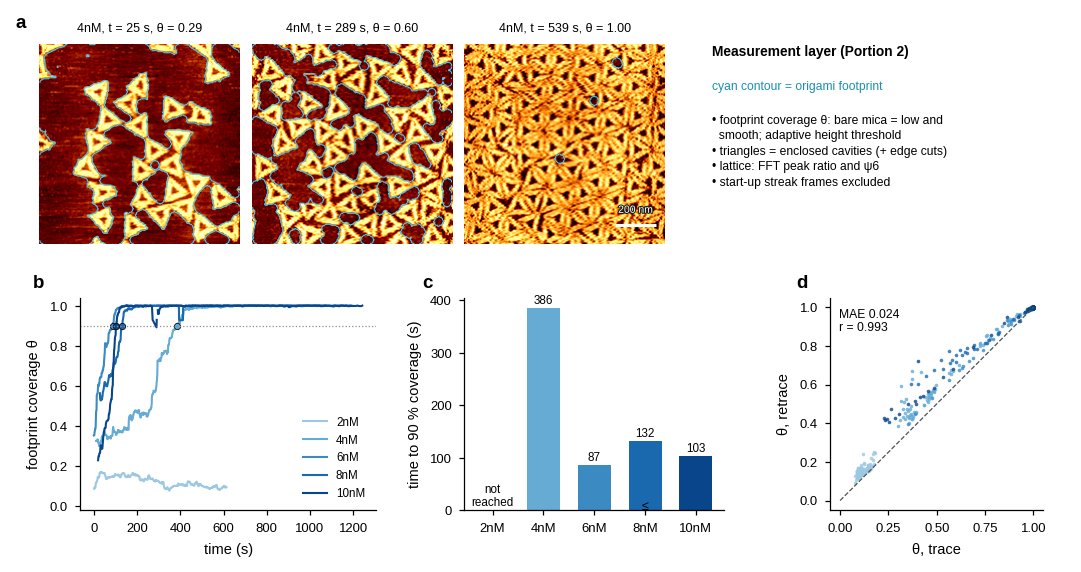

In [6]:
# ---- 4b. Figure 2 — measurement layer and adsorption kinetics -------------------------------------------------------------
def footprint(h, nmpx=5.0):
    T = float(np.clip(0.4 * np.percentile(h, 99), 0.3, 0.8)); w = max(3, int(round(15 / nmpx)) | 1)
    mu = ndi.uniform_filter(h, w); sd = np.sqrt(np.maximum(ndi.uniform_filter(h * h, w) - mu * mu, 0))
    seed = (h < T) & (sd < max(0.25, 3 * np.percentile(sd, 5))); seed = ndi.binary_dilation(seed, iterations=w // 2 + 1) & (h < T)
    r = max(1, int(round(20 / nmpx))); yy, xx = np.mgrid[-r:r + 1, -r:r + 1]
    return ~ndi.binary_opening(seed, structure=(xx ** 2 + yy ** 2) <= r * r)
kin = pd.read_csv(os.path.join(P[4], 'kinetics_clean.csv')).set_index('conc')
rep = pd.read_csv(os.path.join(P[2], 'repeatability_trace_retrace.csv'))
FW, FH = 183.0, 94.0
fig = plt.figure(figsize=(FW * MM, FH * MM)); A = mm_axes(fig, FW, FH)
ex_conc = [c for c in ['4nM', '6nM'] if c in CONCS] or CONCS[:1]
picks = []
for tgt in (0.2, 0.6, 0.995):
    g = lab[lab.conc.isin(ex_conc) & lab.coverage.notna()]
    if len(g): picks.append(int((g.coverage - tgt).abs().idxmin()))
for k, gi in enumerate(picks):
    a = A(6 + k * 36.0, 5, 34, 34); h = np.asarray(X[gi], np.float32)
    a.imshow(h, cmap='afmhot', vmin=-0.5, vmax=2.5); a.contour(footprint(h), levels=[0.5], colors='#3fd0ff', linewidths=0.5); a.axis('off')
    a.set_title(f'{lab.conc[gi]}, t = {lab.t_rel_s[gi]:.0f} s, θ = {lab.coverage[gi]:.2f}', fontsize=6, loc='center')
    if k == 0: panel(a, 'a', x=-0.12, y=1.06)
    if k == len(picks) - 1:
        a.plot([H0 - 50, H0 - 10], [0.9 * H0] * 2, color='white', lw=1.5, solid_capstyle='butt')
        a.text(H0 - 30, 0.85 * H0, '200 nm', color='white', fontsize=5, ha='center', va='bottom', path_effects=[pe.withStroke(linewidth=1.0, foreground='#1a1a1a')])
ax = A(120, 4, 60, 36); ax.axis('off')
ax.text(0.0, 0.97, 'Measurement layer (Portion 2)', fontsize=6.6, weight='bold', va='top')
ax.text(0.0, 0.80, 'cyan contour = origami footprint', fontsize=5.8, va='top', color='#1b8fb5')
ax.text(0.0, 0.64, '• footprint coverage θ: bare mica = low and\n  smooth; adaptive height threshold\n• triangles = enclosed cavities (+ edge cuts)\n'
        '• lattice: FFT peak ratio and ψ6\n• start-up streak frames excluded', fontsize=5.8, va='top', linespacing=1.4)
ax = A(13, 48, 50, 36)
for c in CONCS:
    g = lab[lab.conc == c].sort_values('t_rel_s'); y_ = g.coverage.rolling(5, center=True, min_periods=1).median()
    ax.plot(g.t_rel_s, y_, color=CCOL[c], lw=1.0, label=c)
    if c in kin.index and np.isfinite(kin.loc[c, 't90_s']): ax.plot(kin.loc[c, 't90_s'], 0.9, 'o', ms=3, color=CCOL[c], mec='#0b0b0b', mew=0.4)
ax.axhline(0.9, color='#8f8f8f', ls=':', lw=0.6); ax.set_ylim(-0.02, 1.04); ax.set_xlabel('time (s)'); ax.set_ylabel('footprint coverage θ')
ax.legend(fontsize=5.6, loc='lower right', ncol=1); panel(ax, 'b')
ax = A(78, 48, 44, 36); cs = [c for c in CONCS if c in kin.index]
vals = [kin.loc[c, 't90_s'] for c in cs]
ax.bar(range(len(cs)), np.nan_to_num(vals), color=[CCOL[c] for c in cs], width=0.65)
for i_, (c, v) in enumerate(zip(cs, vals)):
    ax.text(i_, (0 if not np.isfinite(v) else v) + 8, 'not\nreached' if not np.isfinite(v) else f'{v:.0f}', ha='center', fontsize=5.6)
    if bool(kin.loc[c, 'left_censored']): ax.text(i_, 2, '≤', ha='center', fontsize=6)
ax.set_xticks(range(len(cs))); ax.set_xticklabels(cs); ax.set_ylabel('time to 90 % coverage (s)'); panel(ax, 'c')
ax = A(140, 48, 36, 36)
for c in CONCS:
    d = rep[rep.conc == c]; ax.scatter(d.cov_trace, d.cov_retrace, s=3, color=CCOL[c], lw=0, alpha=0.8)
ax.plot([0, 1], [0, 1], ls='--', color='#52514e', lw=0.6); ax.set_xlabel('θ, trace'); ax.set_ylabel('θ, retrace'); ax.set_aspect('equal')
mae_r = np.mean(np.abs(rep.cov_trace - rep.cov_retrace)); r_r = np.corrcoef(rep.cov_trace, rep.cov_retrace)[0, 1]
ax.text(0.04, 0.95, f'MAE {mae_r:.3f}\nr = {r_r:.3f}', transform=ax.transAxes, va='top', fontsize=5.8); panel(ax, 'd')
save(fig, 'Figure2_measurement_and_kinetics')

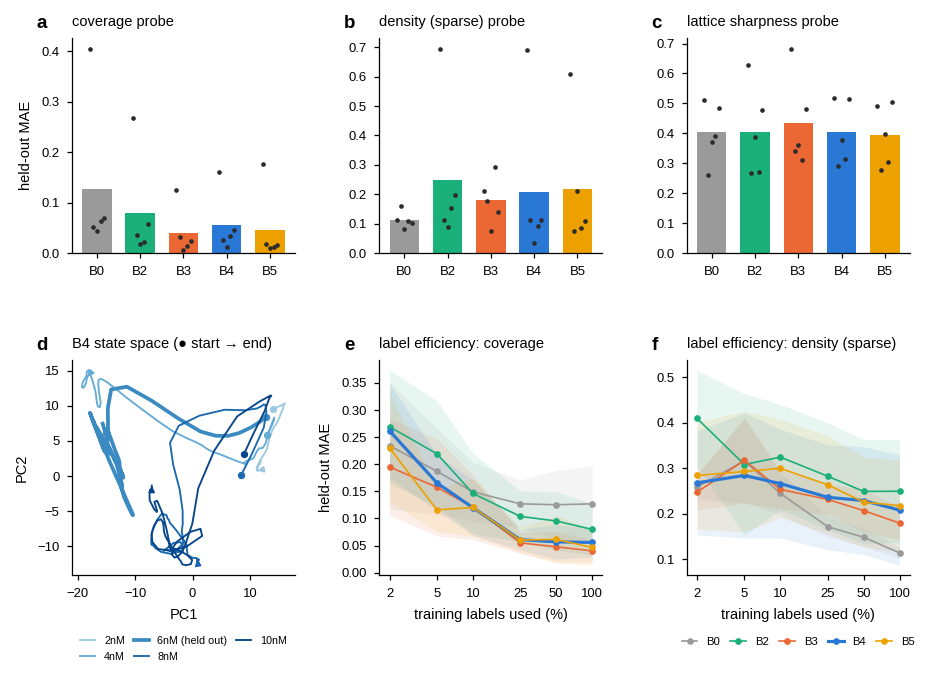

In [7]:
# ---- 4c. Figure 3 — self-supervised representations --------------------------------------------------------------------------
fig = plt.figure(figsize=(W2, 118 * MM)); gs = fig.add_gridspec(2, 3, hspace=0.5, wspace=0.38)
probes_show = [p_ for p_ in ['coverage', 'density (sparse)', 'lattice sharpness'] if p_ in PR.probe.unique()]
VARS = [v for v in ['B0', 'B2', 'B3', 'B4', 'B5'] if v in PR.variant.unique()]
for k, pn in enumerate(probes_show):
    ax = fig.add_subplot(gs[0, k]); d = PR[PR.probe == pn]
    for j, v in enumerate(VARS):
        dv = d[d.variant == v]['value']
        ax.bar(j, dv.mean(), color=VCOL[v], width=0.68)
        ax.scatter(np.full(len(dv), j) + np.linspace(-0.17, 0.17, len(dv)), dv, s=5, color='#2b2b2b', zorder=3, lw=0)
    ax.set_xticks(range(len(VARS))); ax.set_xticklabels(VARS); ax.set_title(f'{pn} probe'); ax.set_ylabel('held-out MAE' if k == 0 else '')
    panel(ax, 'abc'[k])
emb_dir = os.path.join(P[3], p3cfg['config'].get('EMB_SUBDIR', 'embeddings'))
split_show = 'LOCO_6nM' if 'LOCO_6nM' in loco else loco[len(loco) // 2]
ax = fig.add_subplot(gs[1, 0])
f_ = os.path.join(emb_dir, split_show, 'B4.npz')
if os.path.exists(f_):
    Z = np.load(f_, allow_pickle=True)['Z'].astype(np.float32); trm = lab.conc.isin(splits[split_show]['train']).values
    mu = Z[trm].mean(0); _, _, Vt = np.linalg.svd(Z[trm] - mu, full_matrices=False); Pc = (Z - mu) @ Vt[:2].T
    held = splits[split_show]['test'][0]
    for c in CONCS:
        g = lab[lab.conc == c].sort_values('t_rel_s'); pp = Pc[g.index.values]
        k_ = max(1, len(pp) // 60); sm = pd.DataFrame(pp).rolling(k_ * 3, min_periods=1, center=True).mean().values[::k_]
        ax.plot(sm[:, 0], sm[:, 1], color=CCOL[c], lw=1.8 if c == held else 0.9, label=c + (' (held out)' if c == held else ''))
        ax.plot(*sm[0], 'o', ms=2.5, color=CCOL[c]); ax.annotate('', xy=sm[-1], xytext=sm[-2], arrowprops=dict(arrowstyle='-|>', color=CCOL[c], lw=0.8, mutation_scale=6))
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2'); ax.set_title('B4 state space (● start → end)')
    ax.legend(fontsize=5.2, loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=3, handlelength=1.4, columnspacing=0.8)
panel(ax, 'd')
for k, pn in enumerate([p_ for p_ in ['coverage', 'density (sparse)'] if p_ in LE.probe.unique()]):
    ax = fig.add_subplot(gs[1, 1 + k]); d = LE[LE.probe == pn]
    for v in [x for x in VARS if x in d.variant.unique()]:
        g = d[d.variant == v].groupby(['split', 'fraction']).MAE.mean().unstack('split'); mu_ = g.mean(1); se = g.std(1) / np.sqrt(max(1, g.shape[1]))
        ax.plot(g.index, mu_, marker='o', ms=2.2, color=VCOL[v], lw=1.5 if v == 'B4' else 0.8, label=v)
        ax.fill_between(g.index, mu_ - se, mu_ + se, color=VCOL[v], alpha=0.1, lw=0)
    fr_ = sorted(d.fraction.unique()); ax.set_xscale('log'); ax.set_xticks(fr_); ax.set_xticklabels([f'{f*100:g}' for f in fr_]); ax.minorticks_off()
    ax.set_xlabel('training labels used (%)'); ax.set_title(f'label efficiency: {pn}'); ax.set_ylabel('held-out MAE' if k == 0 else '')
    if k == 1: ax.legend(fontsize=5.4, loc='upper center', bbox_to_anchor=(0.5, -0.24), ncol=len(VARS), handlelength=1.4, columnspacing=0.9)
    panel(ax, 'ef'[k])
save(fig, 'Figure3_representations')

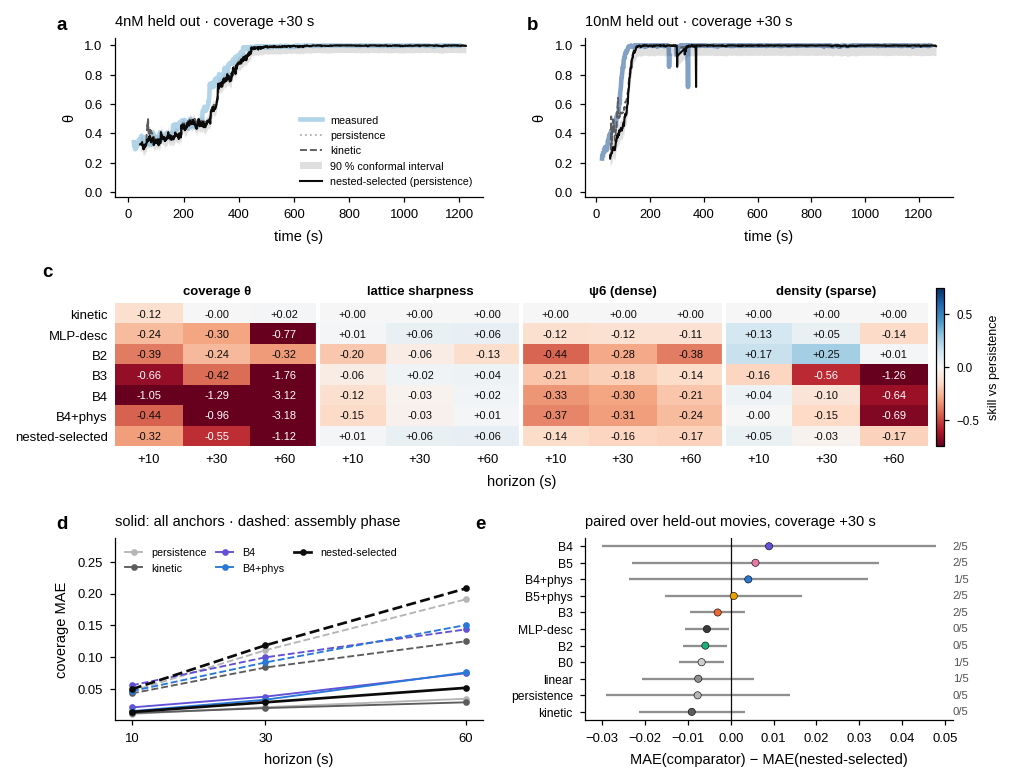

In [8]:
# ---- 4d. Figure 4 — forecasting held-out movies --------------------------------------------------------------------------------
SK = pd.read_csv(os.path.join(P[4], 'skill_vs_persistence.csv'), header=[0, 1], index_col=0)
SK.columns = pd.MultiIndex.from_tuples([(a, float(b)) for a, b in SK.columns])
fig = plt.figure(figsize=(W2, 150 * MM)); gs = fig.add_gridspec(3, 2, height_ratios=[1, 1, 1.15], hspace=0.55, wspace=0.28)
show_movies = [c for c in ['4nM', '10nM'] if c in CONCS] or CONCS[:2]
for k, c in enumerate(show_movies[:2]):
    ax = fig.add_subplot(gs[0, k]); s = f'LOCO_{c}'
    f = os.path.join(P[4], 'predictions', f'{s}.npz')
    if os.path.exists(f):
        R = np.load(f, allow_pickle=True); te = R['te_rows']; o = np.argsort(lab_t[te]); tt = lab_t[te][o] + PH
        rr = np.where(lab.conc.values == c)[0]; ax.plot(lab_t[rr], lab_cov[rr], color=CCOL[c], lw=2.2, alpha=0.5, label='measured')
        for m, ls in [('persistence', ':'), ('kinetic', '--')]:
            if m in R.files: ax.plot(tt, R[m].mean(0)[o, hp, 0], color=MCOL[m], ls=ls, lw=0.9, label=m)
        if SELECTED in R.files:
            p_ = R[SELECTED].mean(0)[o, hp, 0]
            if f'confq_{SELECTED}' in R.files:
                q = R[f'confq_{SELECTED}'][list(p4cfg['config']['CONF_LEVELS']).index(0.9), hp, 0]
                ax.fill_between(tt, np.clip(p_ - q, 0, 1), np.clip(p_ + q, 0, 1), color='#8f8f8f', alpha=0.28, lw=0, label='90 % conformal interval')
            ax.plot(tt, p_, color=MCOL[SELECTED], lw=1.0, label=f'nested-selected ({R["selected_per_target"][0]})')
    ax.set_ylim(-0.03, 1.05); ax.set_xlabel('time (s)'); ax.set_ylabel('θ'); ax.set_title(f'{c} held out · coverage +{PH:.0f} s')
    if k == 0: ax.legend(fontsize=5.2, loc='lower right')
    panel(ax, 'ab'[k])
ax = fig.add_subplot(gs[1, :])
rows_sk = [m for m in ['kinetic', 'MLP-desc', 'B2', 'B3', 'B4', 'B4+phys', SELECTED] if m in SK.index]
cols_sk = [(t, h) for t in ['coverage', 'log_peak', 'psi6', 'log_density'] for h in HORIZONS if (t, h) in SK.columns]
M = SK.loc[rows_sk, cols_sk].values.astype(float); lim = max(0.15, float(np.nanpercentile(np.abs(M), 90)))
im = ax.imshow(M, cmap='RdBu', norm=TwoSlopeNorm(vcenter=0, vmin=-lim, vmax=lim), aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        if np.isfinite(M[i, j]): ax.text(j, i, f'{M[i, j]:+.2f}', ha='center', va='center', fontsize=5.3, color='white' if abs(M[i, j]) > 0.6 * lim else '#0b0b0b')
ax.set_xticks(range(len(cols_sk))); ax.set_xticklabels([f'+{h:.0f}' for _, h in cols_sk]); ax.set_yticks(range(len(rows_sk))); ax.set_yticklabels(rows_sk)
for t in ['coverage', 'log_peak', 'psi6', 'log_density']:
    js = [j for j, (tt_, _) in enumerate(cols_sk) if tt_ == t]
    if js:
        ax.text(np.mean(js), -0.85, TNAME[t], ha='center', va='bottom', fontsize=6.3, weight='bold')
        if js[0] > 0: ax.axvline(js[0] - 0.5, color='white', lw=2)
ax.set_ylim(len(rows_sk) - 0.5, -1.3); ax.tick_params(length=0); ax.set_xlabel('horizon (s)')
for sp_ in ax.spines.values(): sp_.set_visible(False)
cb = plt.colorbar(im, ax=ax, fraction=0.02, pad=0.01); cb.set_label('skill vs persistence', fontsize=6); cb.ax.tick_params(labelsize=5.6)
panel(ax, 'c', x=-0.09, y=1.05)
ax = fig.add_subplot(gs[2, 0])
for m in [x for x in ['persistence', 'kinetic', 'B4', PROPOSED, SELECTED] if x in MODELS]:
    for ph, ls in [('all', '-'), ('assembly', '--')]:
        d = Lm[(Lm.model == m) & (Lm.target == 'coverage') & (Lm.phase == ph)].groupby('horizon').MAE.mean()
        ax.plot(d.index, d.values, ls=ls, marker='o', ms=2.2, color=MCOL[m], lw=1.3 if m == SELECTED else 0.9, label=m if ph == 'all' else None)
ax.set_xticks(HORIZONS); ax.set_xlabel('horizon (s)'); ax.set_ylabel('coverage MAE'); ax.set_title('solid: all anchors · dashed: assembly phase')
ax.set_ylim(top=ax.get_ylim()[1] * 1.32); ax.legend(fontsize=5.2, loc='upper left', ncol=3, handlelength=1.6, columnspacing=0.9); panel(ax, 'd')
ax = fig.add_subplot(gs[2, 1])
fp = ST[(ST.target == 'coverage') & (ST.horizon == PH) & (ST.reference == SELECTED) & (ST.phase == 'all')].sort_values('improvement')
yy = np.arange(len(fp))
ax.hlines(yy, fp.CI95_low, fp.CI95_high, color='#8f8f8f', lw=1.1)
ax.scatter(fp.improvement, yy, s=12, color=[MCOL.get(m, '#2a78d6') for m in fp.comparator], zorder=3, edgecolor='#0b0b0b', lw=0.3)
for y_, (_, r) in zip(yy, fp.iterrows()):
    ax.text(1.0, y_, f'{int(r.won)}/{int(r.n)}', transform=ax.get_yaxis_transform(), va='center', fontsize=5.4, color='#52514e')
ax.axvline(0, color='#0b0b0b', lw=0.6); ax.set_yticks(yy); ax.set_yticklabels(fp.comparator, fontsize=5.8)
ax.set_xlabel('MAE(comparator) − MAE(nested-selected)'); ax.set_title(f'paired over held-out movies, coverage +{PH:.0f} s'); panel(ax, 'e', x=-0.3)
save(fig, 'Figure4_forecasting')

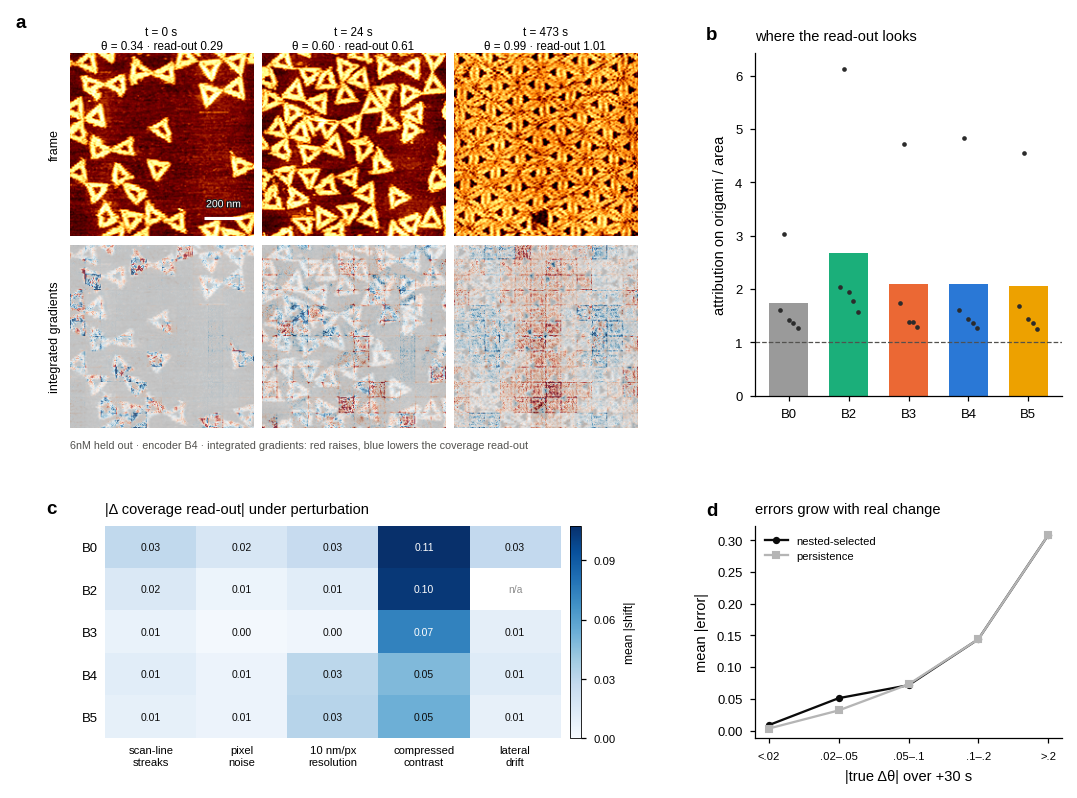

In [9]:
# ---- 4e. Figure 5 — interpretability, robustness and failure anatomy --------------------------------------------------------------
EXA = os.path.join(P[5], 'arrays', 'interpretability_examples.npz')
ATTR = pd.read_csv(os.path.join(P[5], 'attribution_stats.csv')); ROB = pd.read_csv(os.path.join(P[5], 'robustness.csv'))
CA = pd.read_csv(os.path.join(P[5], 'failure_cases.csv'))
FW, FH = 183.0, 136.0
fig = plt.figure(figsize=(FW * MM, FH * MM)); A = mm_axes(fig, FW, FH)
if os.path.exists(EXA):
    E = np.load(EXA, allow_pickle=True); n_ex = len(E['frames']); Hx = E['frames'].shape[-1]
    IM5 = min(31.0, (98.0 - 1.5 * (n_ex - 1)) / max(1, n_ex))
    for i in range(n_ex):
        a = A(10 + i * (IM5 + 1.5), 8, IM5, IM5); a.imshow(E['frames'][i], cmap='afmhot', vmin=-0.5, vmax=2.5); a.axis('off')
        a.set_title(f"t = {float(E['t'][i]):.0f} s\nθ = {E['measured'][i]:.2f} · read-out {E['pred'][i]:.2f}", fontsize=5.6, loc='center', pad=2)
        b = A(10 + i * (IM5 + 1.5), 8 + IM5 + 1.5, IM5, IM5); lim_ = np.percentile(np.abs(E['ig'][i]), 99.5) + 1e-9
        b.imshow(E['frames'][i], cmap='gray', vmin=-0.5, vmax=2.5); b.imshow(E['ig'][i], cmap='RdBu_r', vmin=-lim_, vmax=lim_, alpha=0.75); b.axis('off')
        if i == 0:
            panel(a, 'a', x=-0.3, y=1.12)
            a.text(-0.05, 0.5, 'frame', transform=a.transAxes, rotation=90, ha='right', va='center', fontsize=6)
            b.text(-0.05, 0.5, 'integrated gradients', transform=b.transAxes, rotation=90, ha='right', va='center', fontsize=6)
            a.plot([Hx * 0.94 - 40, Hx * 0.94], [0.9 * Hx] * 2, color='white', lw=1.5, solid_capstyle='butt')
            a.text(Hx * 0.94 - 20, 0.85 * Hx, '200 nm', color='white', fontsize=5, ha='center', va='bottom', path_effects=[pe.withStroke(linewidth=1.0, foreground='#1a1a1a')])
    fig.text((10 + 0.0) / FW, 1 - (8 + 2 * IM5 + 3.5) / FH, f"{E['conc']} held out · encoder {E['variant']} · integrated gradients: red raises, blue lowers the coverage read-out",
             ha='left', va='top', fontsize=5.2, color='#52514e')
ax = A(126, 8, 52, 58)
if len(ATTR):
    ATTR['enrich_origami'] = ATTR.attr_on_origami / ATTR.origami_area
    vv = [v for v in ['B0', 'B2', 'B3', 'B4', 'B5'] if v in ATTR.variant.unique()]
    for j, v in enumerate(vv):
        d = ATTR[ATTR.variant == v].groupby('split').enrich_origami.mean()
        ax.bar(j, d.mean(), color=VCOL[v], width=0.66); ax.scatter(np.full(len(d), j) + np.linspace(-0.15, 0.15, len(d)), d, s=5, color='#2b2b2b', zorder=3, lw=0)
    ax.axhline(1, color='#52514e', ls='--', lw=0.6); ax.set_xticks(range(len(vv))); ax.set_xticklabels(vv)
    ax.set_ylabel('attribution on origami / area'); ax.set_title('where the read-out looks')
panel(ax, 'b')
ax = A(16, 88, 82, 36)
PERTS = list(dict.fromkeys(ROB.perturbation)); vv = [v for v in ['B0', 'B2', 'B3', 'B4', 'B5'] if v in ROB.variant.unique()]
Hm = ROB.groupby(['variant', 'perturbation']).mean_abs_shift.mean().unstack('perturbation').reindex(index=vv, columns=PERTS).values.astype(float)
im = ax.imshow(Hm, cmap='Blues', vmin=0, aspect='auto')
for i in range(Hm.shape[0]):
    for j in range(Hm.shape[1]):
        ax.text(j, i, 'n/a' if not np.isfinite(Hm[i, j]) else f'{Hm[i, j]:.2f}', ha='center', va='center', fontsize=5,
                color='#8f8f8f' if not np.isfinite(Hm[i, j]) else ('white' if Hm[i, j] > 0.6 * np.nanmax(Hm) else '#0b0b0b'))
ax.set_xticks(range(len(PERTS))); ax.set_xticklabels(['\n'.join(p_.rsplit(' ', 1)) for p_ in PERTS], fontsize=5.4, rotation=0)
ax.set_yticks(range(len(vv))); ax.set_yticklabels(vv); ax.tick_params(length=0); ax.set_title('|Δ coverage read-out| under perturbation')
for sp_ in ax.spines.values(): sp_.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02); cb.ax.tick_params(labelsize=5.4); cb.outline.set_linewidth(0.4)
cb.locator = matplotlib.ticker.MaxNLocator(4); cb.update_ticks(); cb.set_label('mean |shift|', fontsize=5.8)
panel(ax, 'c', x=-0.13, y=1.04)
ax = A(126, 88, 52, 36)
if len(CA):
    CA['change_abs'] = (CA.obs - CA.now).abs()
    bins = [-1e-9, 0.02, 0.05, 0.1, 0.2, 1.01]; lb = ['<.02', '.02–.05', '.05–.1', '.1–.2', '>.2']
    CA['bin'] = pd.cut(CA.change_abs, bins, labels=lb); g = CA.groupby('bin', observed=False)[['err', 'err_persistence']].mean()
    ax.plot(range(len(g)), g.err, '-o', ms=2.5, color='#0b0b0b', label=SELECTED); ax.plot(range(len(g)), g.err_persistence, '-s', ms=2.5, color='#b5b5b5', label='persistence')
    ax.set_xticks(range(len(g))); ax.set_xticklabels(lb, fontsize=5.4); ax.set_xlabel(f'|true Δθ| over +{PH:.0f} s'); ax.set_ylabel('mean |error|')
    ax.legend(fontsize=5.4, loc='upper left'); ax.set_title('errors grow with real change')
panel(ax, 'd')
save(fig, 'Figure5_interpretability_robustness')

In [10]:
# ---- 5. Supplementary figures (every analysis figure of Portions 1–5, renumbered) ---------------------------------------------------
sup_src = []
for k in (1, 2, 3):
    sup_src += sorted(glob.glob(os.path.join(P[k], 'figures', '*.png')))
sup_src += sorted(glob.glob(os.path.join(P[4], 'figures', '*.pdf'))) + sorted(glob.glob(os.path.join(P[5], 'figures', '*.pdf')))
for old in glob.glob(os.path.join(SUP, 'S*')):
    os.remove(old)
index = []
for i, src in enumerate(sup_src, start=1):
    dst = os.path.join(SUP, f'S{i:02d}_{os.path.basename(src)}'); shutil.copy2(src, dst)
    index.append(dict(number=f'Supplementary Fig. {i}', file=os.path.basename(dst), source=os.path.relpath(src, DATA_DIR)))
SUPIDX = pd.DataFrame(index); SUPIDX.to_csv(os.path.join(SUP, 'index.csv'), index=False)
print(f'{len(SUPIDX)} supplementary figures copied')

30 supplementary figures copied


In [11]:
# ---- 6. Tables (CSV + LaTeX booktabs + Excel) -----------------------------------------------------------------------------------------
def to_latex_booktabs(df, caption, label, fmt='{:.4g}'):
    def cell(v):
        if isinstance(v, (float, np.floating)):
            return '--' if not np.isfinite(v) else fmt.format(v)
        return str(v).replace('_', r'\_').replace('%', r'\%').replace('&', r'\&').replace('±', r'$\pm$').replace('θ', r'$\theta$').replace('ψ', r'$\psi$').replace('Δ', r'$\Delta$')
    d = df.reset_index()
    cols = [cell(c) if not isinstance(c, tuple) else ' '.join(cell(x) for x in c) for c in d.columns]
    lines = [r'\begin{table}[ht]', r'\centering', r'\small', f'\\caption{{{cell(caption)}}}', f'\\label{{tab:{label}}}',
             r'\begin{tabular}{' + 'l' * 1 + 'r' * (len(cols) - 1) + '}', r'\toprule', ' & '.join(cols) + r' \\', r'\midrule']
    for _, r in d.iterrows():
        lines.append(' & '.join(cell(v) for v in r.values) + r' \\')
    lines += [r'\bottomrule', r'\end{tabular}', r'\end{table}']
    return '\n'.join(lines)
TABLES = {}
def save_table(df, name, caption):
    df.to_csv(os.path.join(TAB, f'{name}.csv')); open(os.path.join(TAB, f'{name}.tex'), 'w').write(to_latex_booktabs(df, caption, name))
    TABLES[name] = (df, caption)
T1 = sessions.groupby('conc').agg(sessions=('session', 'nunique'), frames=('n_frames', 'sum'), kept=('n_kept', 'sum'),
                                  duration_s=('t_end_rel_s', 'max')).reindex(CONCS)
T1['pixel size (nm)'] = [ '/'.join(f'{v:g}' for v in sorted(sessions[sessions.conc == c].nm_per_px.unique())) for c in CONCS]
T1['streak start-up frames'] = [int(streak[lab.conc.values == c].sum()) for c in CONCS]
save_table(T1, 'T1_dataset', 'HS-AFM movies (one per concentration) after quality control.')
T2 = kin[['t50_s', 't90_s', 'left_censored']].copy()
T2.loc['trace–retrace θ MAE / r', 't50_s'] = mae_r; T2.loc['trace–retrace θ MAE / r', 't90_s'] = r_r
save_table(T2, 'T2_kinetics_reliability', 'Observed adsorption kinetics (start-up streak frames removed) and trace-retrace repeatability of coverage.')
T3 = PR.groupby(['probe', 'variant'])['value'].agg(lambda x: f'{x.mean():.4f} ± {x.std():.4f}').unstack('variant')
save_table(T3, 'T3_probes', 'Frozen-encoder probes on held-out movies (mean ± SD over LOCO folds; MAE except regime = balanced accuracy).')
for ph in ['all', 'assembly']:
    d = Lm[(Lm.phase == ph) & (Lm.target == 'coverage') & (Lm.horizon == PH)].pivot(index='model', columns='test', values='MAE')
    d = d.reindex([m for m in MODELS if m in d.index])[[c for c in CONCS if c in d.columns]]
    d['mean'] = d.mean(1); save_table(d, f'T4_forecast_{ph}', f'Coverage MAE at +{PH:.0f} s per held-out movie ({ph} anchors).')
T5 = SK.loc[[m for m in MODELS if m in SK.index]].copy(); T5.columns = [f'{TNAME[a]} +{b:.0f}s' for a, b in T5.columns]
save_table(T5.round(3), 'T5_skill_matrix', 'Forecast skill vs persistence (1 − MAE/MAE_persistence, mean over held-out movies).')
T6 = ST[(ST.target == 'coverage') & (ST.horizon == PH)].set_index(['phase', 'reference', 'comparator'])[
    ['MAE_reference', 'MAE_comparator', 'improvement', 'CI95_low', 'CI95_high', 'cohens_dz', 'won', 'n', 'p', 'q_BH', 'verdict']]
save_table(T6, 'T6_statistics_primary', f'Paired comparisons over held-out movies, coverage +{PH:.0f} s (exact sign-flip test; BH over all endpoints).')
T7 = AUC.groupby(['probe', 'variant']).AUC.agg(['mean', 'std']).unstack('variant')
save_table(T7, 'T7_label_efficiency_auc', 'Area under the label-efficiency curve (mean held-out MAE over log label fraction; lower is better).')
T8 = ROB.groupby(['variant', 'perturbation']).mean_abs_shift.mean().unstack('perturbation')
save_table(T8, 'T8_robustness', 'Mean absolute change of the coverage read-out under imaging perturbations.')
save_table(CLAIMS.set_index('id'), 'T9_claims', 'Pre-specified claims, evidence and verdicts (decision rule in Methods).')
try:
    with pd.ExcelWriter(os.path.join(TAB, 'all_tables.xlsx')) as xw:
        for k_, (df_, cap) in TABLES.items():
            df_.to_excel(xw, sheet_name=k_[:31])
except Exception as e:
    print('Excel export skipped:', e)
print('tables:', sorted(os.listdir(TAB)))

tables: ['T1_dataset.csv', 'T1_dataset.tex', 'T2_kinetics_reliability.csv', 'T2_kinetics_reliability.tex', 'T3_probes.csv', 'T3_probes.tex', 'T4_forecast_all.csv', 'T4_forecast_all.tex', 'T4_forecast_assembly.csv', 'T4_forecast_assembly.tex', 'T5_skill_matrix.csv', 'T5_skill_matrix.tex', 'T6_statistics_primary.csv', 'T6_statistics_primary.tex', 'T7_label_efficiency_auc.csv', 'T7_label_efficiency_auc.tex', 'T8_robustness.csv', 'T8_robustness.tex', 'T9_claims.csv', 'T9_claims.tex', 'all_tables.xlsx']


In [12]:
# ---- 7. Text: figure legends, results summary, methods parameters, manifest, package ---------------------------------------------------
def fmt(x, n=3):
    return '–' if x is None or (isinstance(x, float) and not np.isfinite(x)) else f'{x:.{n}f}'
cprim = ST[(ST.target == 'coverage') & (ST.horizon == PH) & (ST.phase == 'all') & (ST.reference == SELECTED)].set_index('comparator')
t4 = TABLES['T4_forecast_all'][0]
legends = f"""# Figure legends (draft — numbers filled in automatically)

**Figure 1 | Data and workflow.** (a) Analysis pipeline. (b) Flattened HS-AFM height images (5 nm px⁻¹; colour −0.5 to 2.5 nm) of DNA-origami
triangles adsorbing on mica at {', '.join(CONCS)}, at matched times after the first recorded frame; scale bar 200 nm. (c) One track per movie, aligned
with the image rows: footprint coverage θ (5-frame running median, 0 at the bottom and 1 at the top of each grey band) on a logarithmic time axis,
and every recorded frame (grey ticks 200 px at 1 frame s⁻¹, black ticks 400 px at 0.5 frame s⁻¹); dashed lines mark the times shown in (b).

**Figure 2 | Measurement layer and adsorption kinetics.** (a) Footprint-coverage contours on sparse, transition and closed-lattice frames.
(b) Coverage versus time (5-frame running median; start-up streak frames removed); dots mark t90. (c) Time to 90 % coverage:
{', '.join(f'{c} {fmt(kin.loc[c, "t90_s"], 0)} s' for c in CONCS if c in kin.index)}. (d) Trace versus retrace coverage (MAE {mae_r:.3f}, r = {r_r:.3f}).

**Figure 3 | Self-supervised representations.** (a–c) Linear probes of frozen encoders on held-out movies (bars: mean of {NF} leave-one-concentration-out
folds; dots: folds). B0 random initialisation, B2 frame MAE, B3 temporal MAE, B4 temporal MAE + temporal InfoNCE, B5 B4 with shuffled frame order.
(d) Movie trajectories in the B4 embedding space ({split_show}; PCA fitted on training movies only). (e, f) Held-out probe error versus the fraction of
training labels (whole 30-s blocks; mean ± s.e. over held-out movies).

**Figure 4 | Forecasting held-out movies.** (a, b) Coverage forecasts {PH:.0f} s ahead for movies never used in pretraining or training, with the
nested-selected pipeline (per target, the simplest model within one paired standard error of the best inner leave-one-movie-out error) and its
90 % split-conformal interval. (c) Skill versus persistence for every target and horizon (mean over held-out movies).
(d) Coverage error versus horizon for all anchors (solid) and the assembly phase θ < 0.95 (dashed). (e) Paired differences to the nested-selected
pipeline (mean, 95 % CI over held-out movies; numbers = movies in which it was better). With {NF} movies the smallest attainable two-sided
exact p is {2/2**NF:.4f}.

**Figure 5 | Interpretability, robustness and failure anatomy.** (a) Held-out frames and integrated-gradient attribution of the B4 coverage read-out
(red increases, blue decreases the read-out). (b) Attribution enrichment on origami (1 = no preference). (c) Mean absolute change of the coverage
read-out under imaging perturbations. (d) Forecast error versus the true coverage change over the horizon.
"""
open(os.path.join(TXT, 'figure_legends.md'), 'w').write(legends)
S = [f'# Results summary (auto-generated {datetime.now().isoformat(timespec="seconds")})', '']
S.append(f'- Data: {len(CONCS)} movies ({", ".join(CONCS)}), {int(T1.kept.sum())} frames kept after QC; {int(streak.sum())} start-up streak frames excluded from labels.')
S.append(f'- Measurement repeatability: trace–retrace coverage MAE {mae_r:.3f} (r = {r_r:.3f}).')
S.append('- t90 (s): ' + ', '.join(f'{c} {fmt(kin.loc[c, "t90_s"], 0)}' + (' (left-censored)' if bool(kin.loc[c, "left_censored"]) else '') for c in CONCS if c in kin.index) + '.')
if len(PST):
    for _, r in PST[(PST.reference == 'B4') & (PST.comparator == 'B0')].iterrows():
        S.append(f'- Probe "{r.probe}": B4 vs random init improvement {fmt(r.improvement, 4)} [{fmt(r.CI95_low, 4)}, {fmt(r.CI95_high, 4)}], {r.won}/{r.n} folds, p = {fmt(r.p)} → {r.verdict}.')
S.append(f'- Coverage +{PH:.0f} s (LOCO mean MAE): ' + ', '.join(f'{m} {t4.loc[m, "mean"]:.4f}' for m in ['persistence', 'kinetic', PROPOSED, SELECTED] if m in t4.index) + '.')
for comp in ['persistence', 'kinetic']:
    if comp in cprim.index:
        r = cprim.loc[comp]
        S.append(f'- Nested-selected vs {comp}: Δ = {fmt(r.improvement, 4)} [{fmt(r.CI95_low, 4)}, {fmt(r.CI95_high, 4)}], d_z = {fmt(r.cohens_dz, 2)}, '
                 f'{int(r.won)}/{int(r.n)} movies, p = {fmt(r.p)}, q = {fmt(r.q_BH)} → {r.verdict}.')
if SELECTED in SK.index:
    best_cells = SK.loc[SELECTED].sort_values(ascending=False).head(3)
    S.append('- Largest skill of the nested-selected pipeline: ' + ', '.join(f'{TNAME[a]} +{b:.0f} s {v:+.3f}' for (a, b), v in best_cells.items()) + '.')
if len(BOOT):
    for _, r in BOOT[BOOT.model == SELECTED].iterrows():
        S.append(f'- {r.test}: nested-selected improvement over persistence {r.improvement_vs_persistence:+.4f} (within-movie 95 % CI {r.CI95_low:+.4f} to {r.CI95_high:+.4f}).')
S.append('- Claims: ' + '; '.join(f'{r.id} {r.verdict}' for _, r in CLAIMS.iterrows()) + '.')
S.append(f'\nAll p-values are exact two-sided sign-flip tests over {NF} held-out movies (minimum attainable p = {2/2**NF:.4f}); q = Benjamini–Hochberg over all {len(ST)} endpoint comparisons.')
if QUICK:
    S.append('\n**WARNING: Portion 3 ran in QUICK mode — these numbers only prove the pipeline runs.**')
open(os.path.join(TXT, 'results_summary.md'), 'w').write('\n'.join(S)); print('\n'.join(S))
params = {f'portion{k}': json.load(open(f)) for k, f in [(3, os.path.join(P[3], 'run_config_portion3.json')), (4, os.path.join(P[4], 'run_config_portion4_v2.json')),
                                                          (5, os.path.join(P[5], 'run_config_portion5.json'))] if os.path.exists(f)}
json.dump(params, open(os.path.join(TXT, 'methods_parameters.json'), 'w'), indent=1, default=str)
def md5(p_):
    h = hashlib.md5()
    with open(p_, 'rb') as f:
        for b_ in iter(lambda: f.read(1 << 20), b''): h.update(b_)
    return h.hexdigest()
man = dict(created=datetime.now().isoformat(timespec='seconds'), python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__,
           matplotlib=matplotlib.__version__, font=FONT, files={})
for d_ in list(P.values()) + [OUT]:
    for p_ in sorted(glob.glob(os.path.join(d_, '*.csv')) + glob.glob(os.path.join(d_, '*.json'))):
        man['files'][os.path.relpath(p_, DATA_DIR)] = md5(p_)
json.dump(man, open(os.path.join(TXT, 'reproducibility_manifest.json'), 'w'), indent=1)
zpath = os.path.join(OUT, 'publication_package.zip')
with zipfile.ZipFile(zpath, 'w', zipfile.ZIP_DEFLATED) as z:
    for d_ in [FIG, SUP, TAB, TXT]:
        for p_ in sorted(glob.glob(os.path.join(d_, '*'))):
            z.write(p_, os.path.relpath(p_, OUT))
    for p_ in glob.glob(os.path.join(OUT, '*.csv')):
        z.write(p_, os.path.relpath(p_, OUT))
print(f'publication package: {zpath} ({os.path.getsize(zpath)/1e6:.1f} MB)')
print('main figures:', sorted(f for f in os.listdir(FIG) if f.endswith('.pdf')))

# Results summary (auto-generated 2026-10-16T06:06:22)

- Data: 5 movies (2nM, 4nM, 6nM, 8nM, 10nM), 4036 frames kept after QC; 87 start-up streak frames excluded from labels.
- Measurement repeatability: trace–retrace coverage MAE 0.024 (r = 0.993).
- t90 (s): 2nM –, 4nM 386, 6nM 87, 8nM 132 (left-censored), 10nM 103.
- Probe "coverage": B4 vs random init improvement 0.0712 [-0.0486, 0.1910], 5/5 folds, p = 0.062 → SUPPORTED.
- Probe "density (sparse)": B4 vs random init improvement -0.0942 [-0.4306, 0.2423], 3/5 folds, p = 0.938 → NOT SUPPORTED.
- Probe "lattice sharpness": B4 vs random init improvement 0.0011 [-0.0528, 0.0551], 1/5 folds, p = 1.000 → INCONCLUSIVE.
- Probe "regime": B4 vs random init improvement 0.0528 [-0.0245, 0.1301], 4/5 folds, p = 0.125 → SUPPORTED.
- Probe "Δcoverage +30 s": B4 vs random init improvement -0.0064 [-0.0263, 0.0134], 3/5 folds, p = 0.500 → NOT SUPPORTED.
- Probe "ψ6 (dense)": B4 vs random init improvement -0.0054 [-0.0293, 0.0186], 2/4 folds, p = 

## Outputs (`portion6_outputs/`)
| Folder / file | Content |
|---|---|
| `main_figures/Figure1…5.{pdf,png,tiff}` | journal figures at 183 mm, 7-pt type, panel letters; PDF is vector (editable text), PNG/TIFF 600 dpi |
| `supplementary_figures/S01…` + `index.csv` | every analysis figure of Portions 1–5, renumbered |
| `tables/T1…T9.{csv,tex}`, `all_tables.xlsx` | dataset, kinetics & reliability, probes, forecasting, skill, statistics, label efficiency, robustness, claims |
| `statistics_*.csv`, `claims_table.csv`, `block_bootstrap_vs_persistence.csv` | the full statistical record |
| `text/figure_legends.md`, `text/results_summary.md` | draft legends and results paragraph with every number filled in |
| `text/methods_parameters.json`, `text/reproducibility_manifest.json` | all settings of Portions 3–5; MD5 of every result table |
| `publication_package.zip` | everything above in one file for co-authors / submission |